In [10]:
!pip install kagglehub

Load dataset

In [11]:
import kagglehub

# Download the PlantVillage dataset
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


In [ ]:
import os

for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")
    # only go 3 levels deep so the output isn't huge
    if root.count(os.sep) - path.count(os.sep) >= 2:
        dirs.clear()

/kaggle/input/plantvillage-dataset -> 0 files
/kaggle/input/plantvillage-dataset/plantvillage dataset -> 0 files
/kaggle/input/plantvillage-dataset/plantvillage dataset/segmented -> 0 files
/kaggle/input/plantvillage-dataset/plantvillage dataset/grayscale -> 0 files
/kaggle/input/plantvillage-dataset/plantvillage dataset/color -> 0 files


In [ ]:
import kagglehub

path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


Import required libraries

In [ ]:
import os
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

In [ ]:
for item in os.listdir(path):
    print(item)

plantvillage dataset


In [ ]:
print(os.listdir(Path(path) / "plantvillage dataset"))

['segmented', 'grayscale', 'color']


In [ ]:
COLOR_DIR = Path(path) / "plantvillage dataset" / "color"

print(COLOR_DIR.exists())
print(len(os.listdir(COLOR_DIR)), "class folders")

True
38 class folders


In [9]:
files = [p for p in COLOR_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
df = pd.DataFrame({"path": files, "label": [p.parent.name for p in files]})
df["crop"] = df["label"].str.split("___").str[0]
df["disease"] = df["label"].str.split("___").str[1]

In [12]:
print(df.shape)

(54305, 4)


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54305 entries, 0 to 54304
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   path     54305 non-null  object
 1   label    54305 non-null  object
 2   crop     54305 non-null  object
 3   disease  54305 non-null  object
dtypes: object(4)
memory usage: 1.7+ MB


In [14]:
print(df.isnull().sum())

path       0
label      0
crop       0
disease    0
dtype: int64


In [15]:
counts = df["label"].value_counts()
print(counts)
print("Biggest:", counts.idxmax(), counts.max())
print("Smallest:", counts.idxmin(), counts.min())
print("Imbalance ratio:", round(counts.max() / counts.min(), 1))



label
Orange___Haunglongbing_(Citrus_greening)              5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
Soybean___healthy                                     5090
Peach___Bacterial_spot                                2297
Tomato___Bacterial_spot                               2127
Tomato___Late_blight                                  1909
Squash___Powdery_mildew                               1835
Tomato___Septoria_leaf_spot                           1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
Apple___healthy                                       1645
Tomato___healthy                                      1591
Blueberry___healthy                                   1502
Pepper,_bell___healthy                                1478
Tomato___Target_Spot                                  1404
Grape___Esca_(Black_Measles)                          1383
Corn_(maize)___Common_rust_                           1192
Grape___Black_rot                                 

Locate the dataset

In [16]:
print("Dataset location:", path)

print("\nFolders inside dataset:")

for folder in os.listdir(path):
    print(folder)

Dataset location: /kaggle/input/plantvillage-dataset

Folders inside dataset:
plantvillage dataset


Selecting the image dataset folder

In [17]:
# Find the color folder
dataset_dir = None

for root, dirs, files in os.walk(path):
    if os.path.basename(root).lower() == "color":
        dataset_dir = root
        break

# If color folder is not found, use the downloaded folder
if dataset_dir is None:
    dataset_dir = path

print("Selected dataset folder:", dataset_dir)

Selected dataset folder: /kaggle/input/plantvillage-dataset/plantvillage dataset/color


then display the class folders:

In [18]:
classes = os.listdir(dataset_dir)

print("Total folders:", len(classes))
print("\nClass names:")

for name in classes:
    if os.path.isdir(os.path.join(dataset_dir, name)):
        print(name)

Total folders: 38

Class names:
Tomato___Late_blight
Tomato___healthy
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Soybean___healthy
Squash___Powdery_mildew
Potato___healthy
Corn_(maize)___Northern_Leaf_Blight
Tomato___Early_blight
Tomato___Septoria_leaf_spot
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Strawberry___Leaf_scorch
Peach___healthy
Apple___Apple_scab
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Bacterial_spot
Apple___Black_rot
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Peach___Bacterial_spot
Apple___Cedar_apple_rust
Tomato___Target_Spot
Pepper,_bell___healthy
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Potato___Late_blight
Tomato___Tomato_mosaic_virus
Strawberry___healthy
Apple___healthy
Grape___Black_rot
Potato___Early_blight
Cherry_(including_sour)___healthy
Corn_(maize)___Common_rust_
Grape___Esca_(Black_Measles)
Raspberry___healthy
Tomato___Leaf_Mold
Tomato___Spider_mites Two-spotted_spider_mite
Pepper,_bell___Bacterial_spot
Corn_(m

Calculating the  total images and class distribution

In [19]:
# Store image counts
class_counts = {}

# Image file formats
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

for class_name in os.listdir(dataset_dir):

    class_path = os.path.join(dataset_dir, class_name)

    if os.path.isdir(class_path):

        images = [
            file for file in os.listdir(class_path)
            if file.lower().endswith(image_extensions)
        ]

        class_counts[class_name] = len(images)

# Display the results
for class_name, count in class_counts.items():
    print(class_name, ":", count)

print("\nTotal images:", sum(class_counts.values()))
print("Total classes:", len(class_counts))

Tomato___Late_blight : 1909
Tomato___healthy : 1591
Grape___healthy : 423
Orange___Haunglongbing_(Citrus_greening) : 5507
Soybean___healthy : 5090
Squash___Powdery_mildew : 1835
Potato___healthy : 152
Corn_(maize)___Northern_Leaf_Blight : 985
Tomato___Early_blight : 1000
Tomato___Septoria_leaf_spot : 1771
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513
Strawberry___Leaf_scorch : 1109
Peach___healthy : 360
Apple___Apple_scab : 630
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 5357
Tomato___Bacterial_spot : 2127
Apple___Black_rot : 621
Blueberry___healthy : 1502
Cherry_(including_sour)___Powdery_mildew : 1052
Peach___Bacterial_spot : 2297
Apple___Cedar_apple_rust : 275
Tomato___Target_Spot : 1404
Pepper,_bell___healthy : 1478
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076
Potato___Late_blight : 1000
Tomato___Tomato_mosaic_virus : 373
Strawberry___healthy : 456
Apple___healthy : 1645
Grape___Black_rot : 1180
Potato___Early_blight : 1000
Cherry_(including_sour)___healthy : 854
Corn_

Visualize class distribution

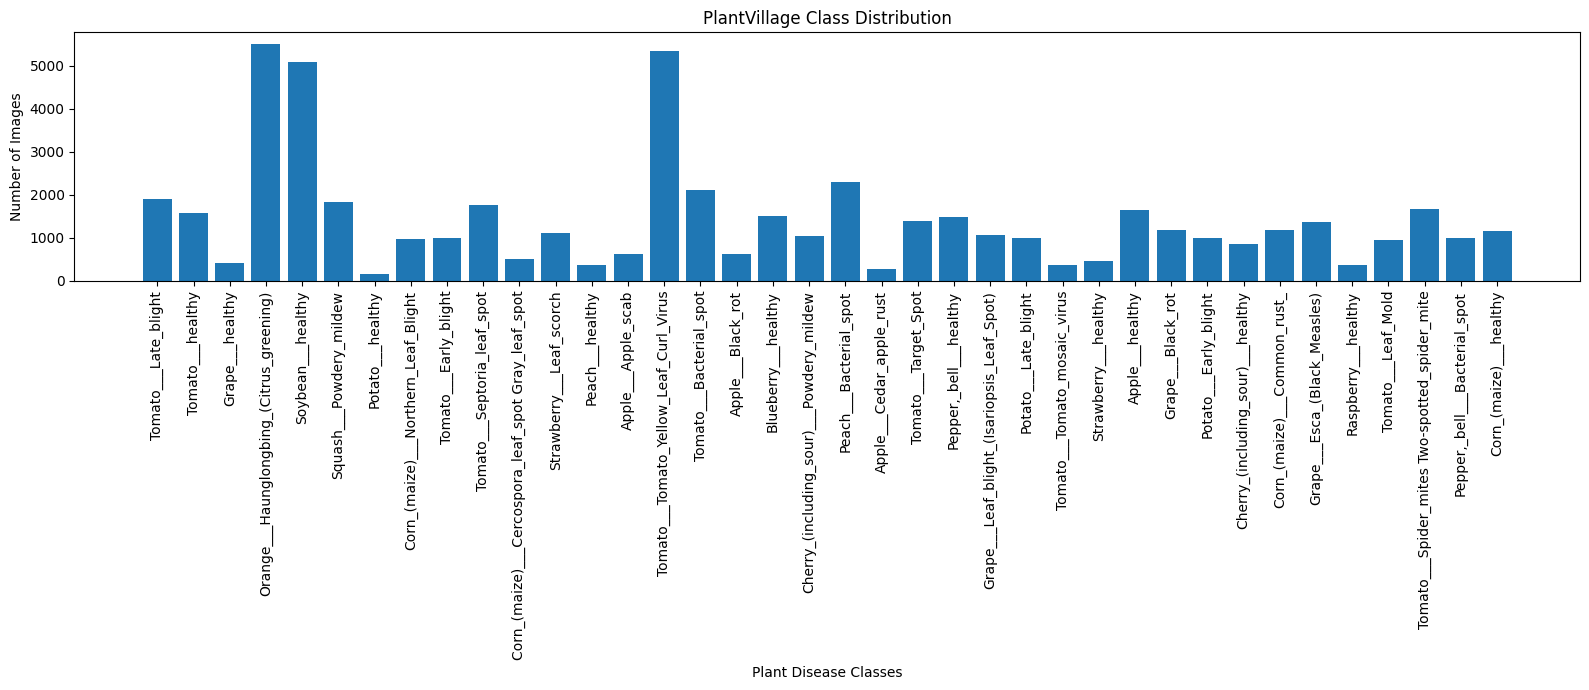

In [20]:
plt.figure(figsize=(16, 7))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("PlantVillage Class Distribution")
plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

Create a class distribution table

In [21]:
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Disease Class", "Image Count"]
)

df["Percentage"] = (
    df["Image Count"] / df["Image Count"].sum()
) * 100

df = df.sort_values(
    by="Image Count",
    ascending=False
)

display(df)

,Disease Class,Image Count,Percentage
3,Orange___Haunglongbing_(Citrus_greening),5507,10.140871
14,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.864653
4,Soybean___healthy,5090,9.372986
19,Peach___Bacterial_spot,2297,4.229813
15,Tomato___Bacterial_spot,2127,3.916766
0,Tomato___Late_blight,1909,3.515330
5,Squash___Powdery_mildew,1835,3.379063
9,Tomato___Septoria_leaf_spot,1771,3.261210
35,Tomato___Spider_mites Two-spotted_spider_mite,1676,3.086272
27,Apple___healthy,1645,3.029187


Image visualization

Display sample images

In [22]:
from PIL import Image

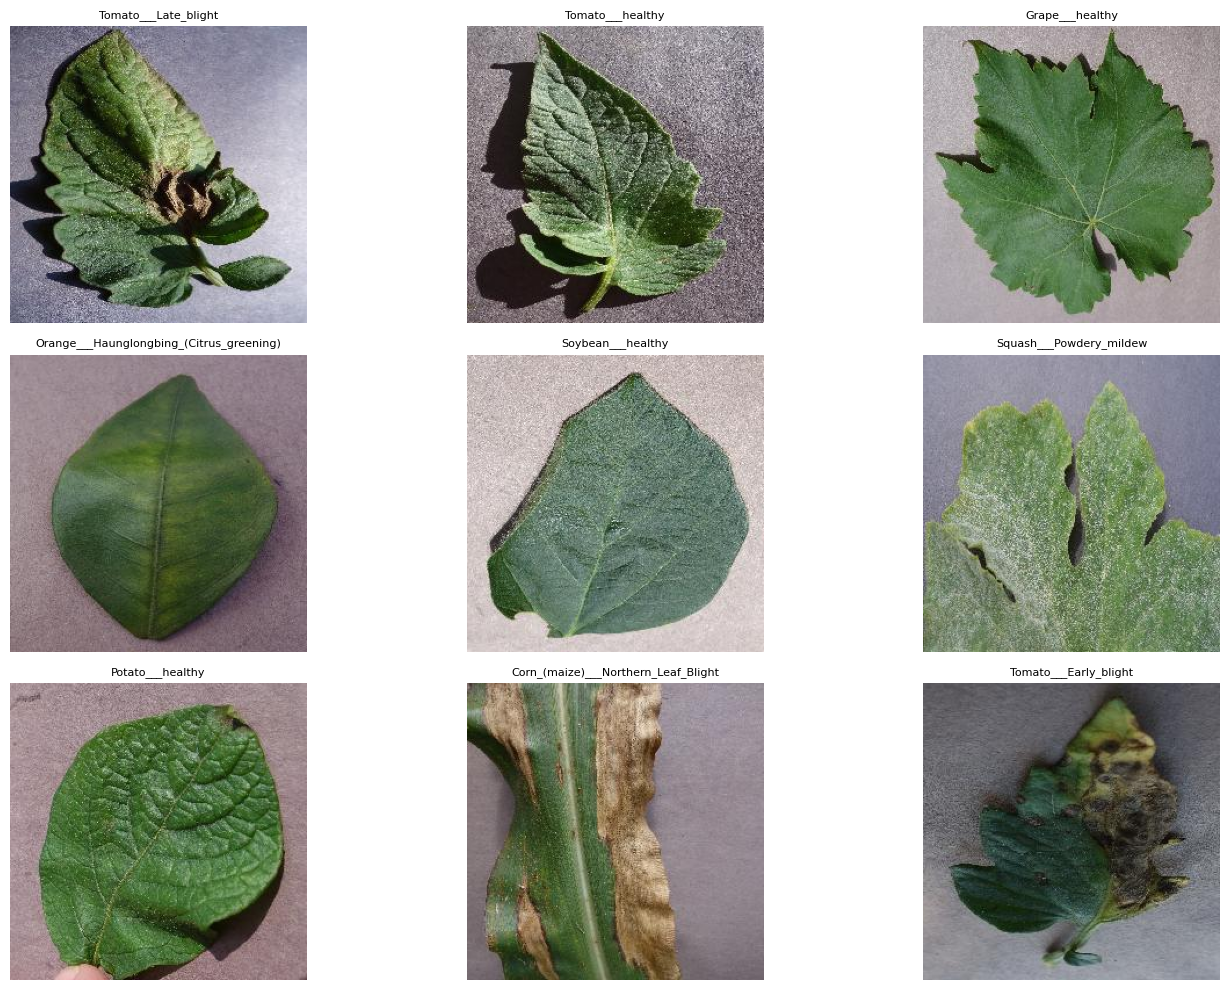

In [23]:
plt.figure(figsize=(15, 10))

class_names = list(class_counts.keys())

for i in range(min(9, len(class_names))):

    class_name = class_names[i]

    class_path = os.path.join(dataset_dir, class_name)

    images = os.listdir(class_path)

    image_path = os.path.join(class_path, images[0])

    img = Image.open(image_path)

    plt.subplot(3, 3, i + 1)

    plt.imshow(img)
    plt.title(class_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

Image statistics

In here we will calculate:
1. Image width and height.
2. Image dimensions.
3. Image color mode.
4. Average pixel intensity.
5. RGB channel statistics.

Collecting image dimensions

In [24]:
image_data = []
for class_name in class_counts:
    class_path = os.path.join(dataset_dir, class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith(image_extensions):
            image_path = os.path.join(class_path, file)

            try:
                img = Image.open(image_path)
                width, height = img.size
                image_data.append({
                    "Class": class_name,
                    "Image": file,
                    "Width": width,
                    "Height": height,
                    "Mode": img.mode
                })

            except Exception:
                print("Cannot read:", image_path)

# Convert into a DataFrame
image_df = pd.DataFrame(image_data)

display(image_df.head())

,Class,Image,Width,Height,Mode
0,Tomato___Late_blight,781e93a9-2059-42de-8075-658033a6abf7___RS_Late...,256,256,RGB
1,Tomato___Late_blight,283ff0be-6e5e-4b4e-bf21-639780b77ffc___GHLB2 L...,256,256,RGB
2,Tomato___Late_blight,0db85707-41f9-42df-ba3b-842d14f00a68___GHLB2 L...,256,256,RGB
3,Tomato___Late_blight,078a999d-6e6f-427e-a1e6-80b4d2df2bae___GHLB2 L...,256,256,RGB
4,Tomato___Late_blight,3dcee9ed-43bb-45a9-8cff-641b3dd62179___RS_Late...,256,256,RGB


Analyze image dimensions

In [25]:
print("Average width:", image_df["Width"].mean())
print("Average height:", image_df["Height"].mean())
print("Minimum width:", image_df["Width"].min())
print("Maximum width:", image_df["Width"].max())
print("Minimum height:", image_df["Height"].min())
print("Maximum height:", image_df["Height"].max())

Average width: 256.0
Average height: 256.0
Minimum width: 256
Maximum width: 256
Minimum height: 256
Maximum height: 256


Analyze image color modes

In [26]:
print(image_df["Mode"].value_counts())

Mode
RGB     54304
RGBA        1
Name: count, dtype: int64


Pixel intensity and RGB statistics

 Calculate average RGB values

In [27]:
rgb_values = []

for class_name in class_counts:
    class_path = os.path.join(dataset_dir, class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith(image_extensions):
            image_path = os.path.join(class_path, file)

            try:
                img = Image.open(image_path).convert("RGB")
                img_array = np.array(img)
                red = img_array[:, :, 0].mean()
                green = img_array[:, :, 1].mean()
                blue = img_array[:, :, 2].mean()
                rgb_values.append({
                    "Class": class_name,
                    "Red": red,
                    "Green": green,
                    "Blue": blue
                })

            except Exception:
                continue
rgb_df = pd.DataFrame(rgb_values)

display(rgb_df.head())

,Class,Red,Green,Blue
0,Tomato___Late_blight,118.074341,123.951462,116.241089
1,Tomato___Late_blight,110.735855,113.335632,117.720367
2,Tomato___Late_blight,123.608154,123.146225,120.731522
3,Tomato___Late_blight,125.018692,121.474289,114.513916
4,Tomato___Late_blight,105.345154,104.614120,88.532928


Visualize RGB statistics

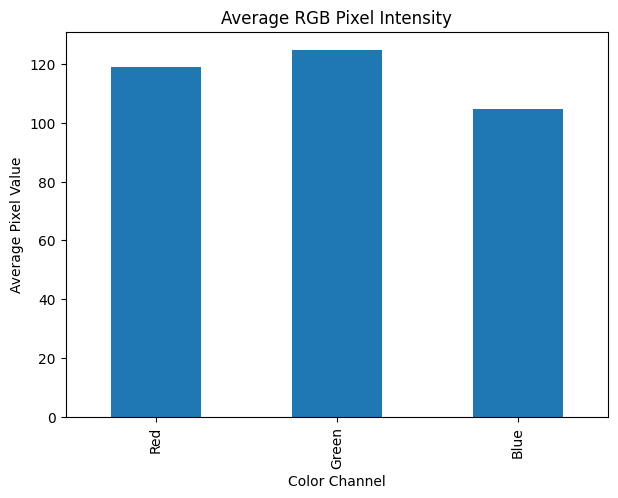

In [28]:
rgb_means = rgb_df[["Red", "Green", "Blue"]].mean()

plt.figure(figsize=(7, 5))

rgb_means.plot(kind="bar")

plt.title("Average RGB Pixel Intensity")
plt.xlabel("Color Channel")
plt.ylabel("Average Pixel Value")

plt.show()

Image quality assessment

Check corrupted images

In [29]:
corrupted_images = []

for class_name in class_counts:

    class_path = os.path.join(dataset_dir, class_name)

    for file in os.listdir(class_path):

        if file.lower().endswith(image_extensions):

            image_path = os.path.join(class_path, file)

            try:
                img = Image.open(image_path)
                img.verify()

            except Exception:
                corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

Total corrupted images: 0


Check image brightness

In [30]:
brightness_values = []

for class_name in class_counts:

    class_path = os.path.join(dataset_dir, class_name)

    for file in os.listdir(class_path):

        if file.lower().endswith(image_extensions):

            image_path = os.path.join(class_path, file)

            try:
                img = Image.open(image_path).convert("L")

                brightness = np.array(img).mean()

                brightness_values.append(brightness)

            except Exception:
                continue

print("Average brightness:", np.mean(brightness_values))
print("Minimum brightness:", np.min(brightness_values))
print("Maximum brightness:", np.max(brightness_values))

Average brightness: 120.7031506301575
Minimum brightness: 8.2462158203125
Maximum brightness: 235.0587615966797


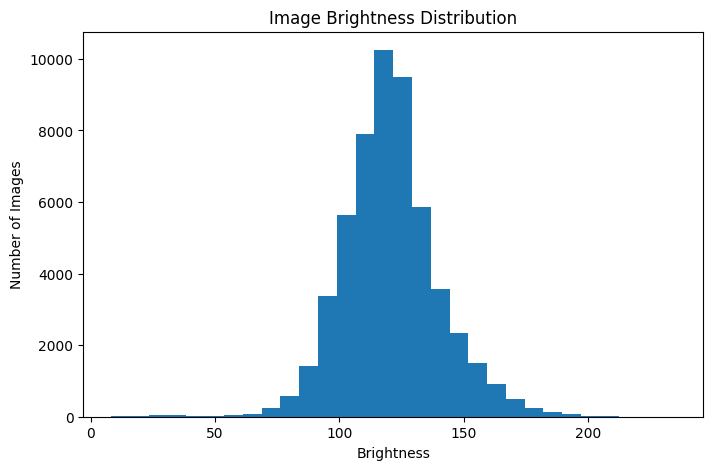

In [31]:
plt.figure(figsize=(8, 5))

plt.hist(brightness_values, bins=30)

plt.title("Image Brightness Distribution")
plt.xlabel("Brightness")
plt.ylabel("Number of Images")

plt.show()

Detect blurry images

In [32]:
import cv2

In [33]:
sharpness_values = []

for class_name in class_counts:

    class_path = os.path.join(dataset_dir, class_name)

    images = os.listdir(class_path)

    # Check only 50 images from each class
    for file in images[:50]:

        if file.lower().endswith(image_extensions):

            image_path = os.path.join(class_path, file)

            try:
                img = cv2.imread(image_path)

                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

                sharpness = cv2.Laplacian(
                    gray,
                    cv2.CV_64F
                ).var()

                sharpness_values.append(sharpness)

            except Exception:
                continue

print("Average sharpness:", np.mean(sharpness_values))

Average sharpness: 4118.5467364592005


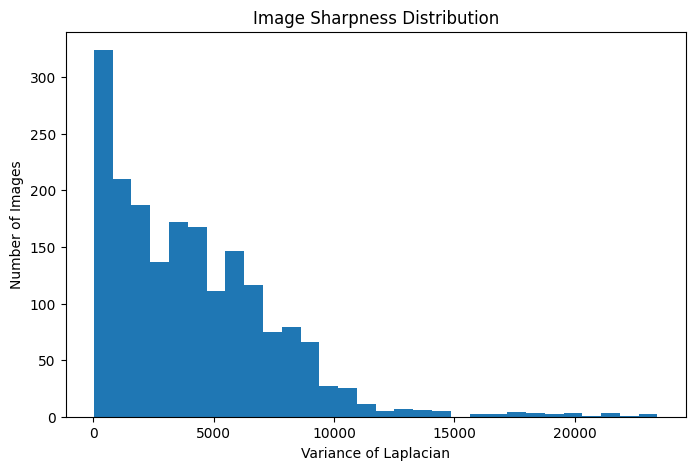

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(sharpness_values, bins=30)

plt.title("Image Sharpness Distribution")
plt.xlabel("Variance of Laplacian")
plt.ylabel("Number of Images")

plt.show()

Detect duplicate images

In [35]:
import hashlib
image_hashes = {}
for class_name in class_counts:
    class_path = os.path.join(dataset_dir, class_name)
    for file in os.listdir(class_path):
        if file.lower().endswith(image_extensions):
            image_path = os.path.join(class_path, file)
            try:
                with open(image_path, "rb") as f:

                    image_hash = hashlib.md5(
                        f.read()
                    ).hexdigest()

                if image_hash in image_hashes:
                    image_hashes[image_hash].append(image_path)
                else:
                    image_hashes[image_hash] = [image_path]

            except Exception:
                continue

duplicates = [
    files for files in image_hashes.values()
    if len(files) > 1
]

print("Number of duplicate groups:", len(duplicates))

Number of duplicate groups: 21


Generating the final EDA summary

In [36]:
print("========== PLANTVILLAGE EDA SUMMARY ==========")

print("Total Classes:", len(class_counts))

print("Total Images:", sum(class_counts.values()))

print("Average Images Per Class:", np.mean(list(class_counts.values())))

print("Minimum Class Images:", min(class_counts.values()))

print("Maximum Class Images:", max(class_counts.values()))

print("Average Image Width:", image_df["Width"].mean())

print("Average Image Height:", image_df["Height"].mean())

print("Corrupted Images:", len(corrupted_images))

print("Average Brightness:", np.mean(brightness_values))

print("Average Sharpness:", np.mean(sharpness_values))

print("Duplicate Groups:", len(duplicates))

print("===============================================")

========== PLANTVILLAGE EDA SUMMARY ==========
Total Classes: 38
Total Images: 54305
Average Images Per Class: 1429.078947368421
Minimum Class Images: 152
Maximum Class Images: 5507
Average Image Width: 256.0
Average Image Height: 256.0
Corrupted Images: 0
Average Brightness: 120.7031506301575
Average Sharpness: 4118.5467364592005
Duplicate Groups: 21


Find the most and least represented classes

In [37]:
# Sort classes by image count
sorted_classes = df.sort_values(
    by="Image Count",
    ascending=False
)

print("Top 5 classes:")
display(sorted_classes.head(5))

print("Bottom 5 classes:")
display(sorted_classes.tail(5))

Top 5 classes:


,Disease Class,Image Count,Percentage
3,Orange___Haunglongbing_(Citrus_greening),5507,10.140871
14,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.864653
4,Soybean___healthy,5090,9.372986
19,Peach___Bacterial_spot,2297,4.229813
15,Tomato___Bacterial_spot,2127,3.916766


Bottom 5 classes:


,Disease Class,Image Count,Percentage
25,Tomato___Tomato_mosaic_virus,373,0.686861
33,Raspberry___healthy,371,0.683178
12,Peach___healthy,360,0.662922
20,Apple___Cedar_apple_rust,275,0.506399
6,Potato___healthy,152,0.279901


Visualize the 10 largest and smallest classes

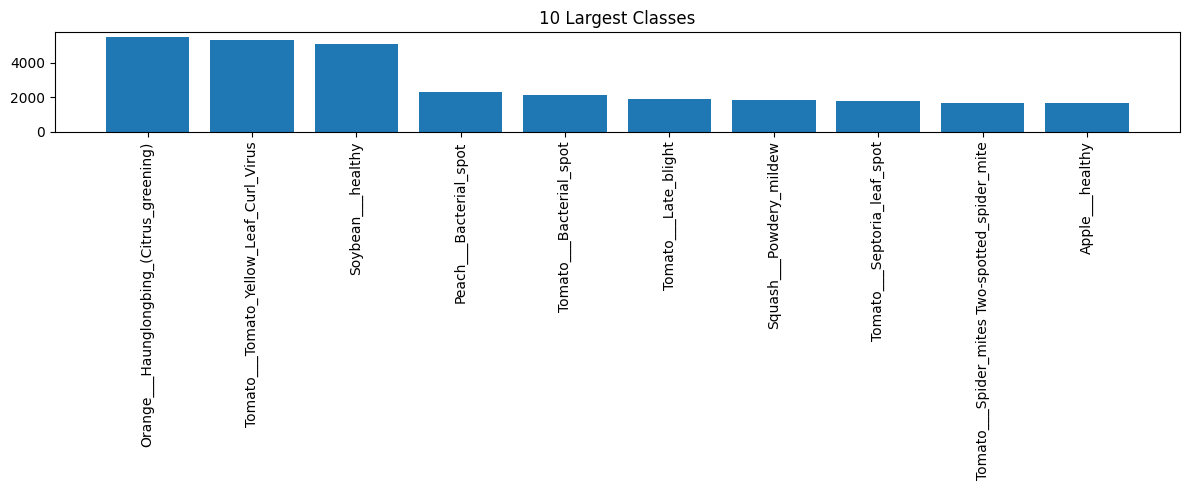

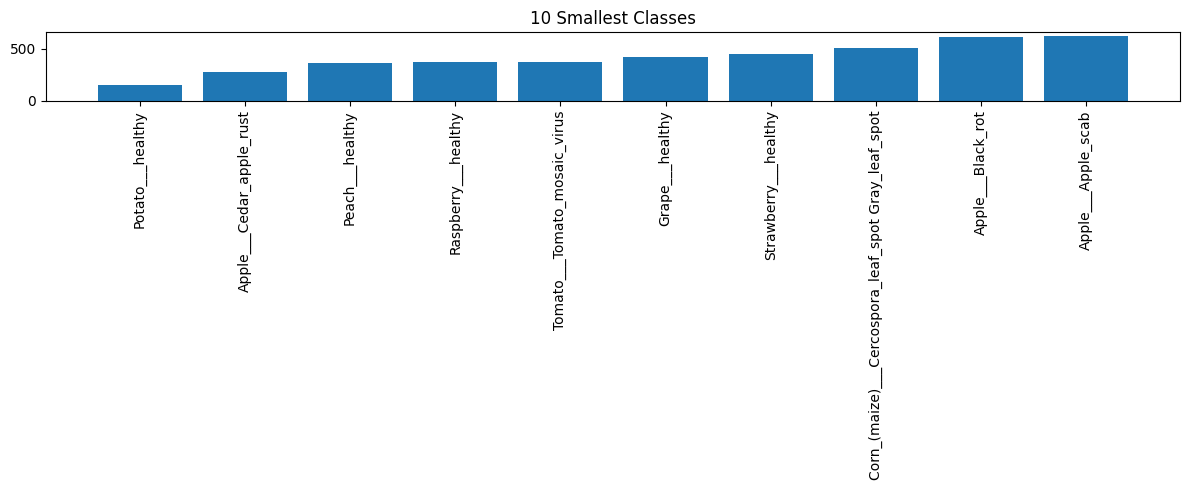

In [38]:
top_10 = df.nlargest(10, "Image Count")

bottom_10 = df.nsmallest(10, "Image Count")

plt.figure(figsize=(12, 5))

plt.bar(top_10["Disease Class"], top_10["Image Count"])

plt.title("10 Largest Classes")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.bar(bottom_10["Disease Class"], bottom_10["Image Count"])

plt.title("10 Smallest Classes")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [39]:
print("Duplicate groups:", len(duplicates))

for group in duplicates[:5]:

    print("\nDuplicate group:")

    for image in group:
        print(image)

Duplicate groups: 21

Duplicate group:
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/d82b634e-9a19-497b-b698-aaf100d622a1___GHLB_PS Leaf 24 Day 13.jpg
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/861d8b00-57a4-46b0-b51a-09d102dbe119___GHLB_PS Leaf 24 Day 13.jpg

Duplicate group:
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS Leaf 23.7 Day 13.jpg
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS Leaf 23.7 Day 13.jpg

Duplicate group:
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/e20107e7-137f-400e-817f-5dc4c58e5d70___GHLB2 Leaf 8677.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/5688ea99-c949-41d0-bbab-9cbf0ffb8bcd___GHLB2 Leaf 8677.JPG

Duplicate group:
/kaggle/input/plantvill

In [40]:
import os
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import kagglehub
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

COLOR_DIR = Path(path) / "plantvillage dataset" / "color"

print(COLOR_DIR.exists())
print(len(os.listdir(COLOR_DIR)), "class folders")

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
True
38 class folders


In [41]:
files = [p for p in COLOR_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
data_df = pd.DataFrame({"path": files, "label": [p.parent.name for p in files]})

data_df["hash"] = [hashlib.md5(p.read_bytes()).hexdigest() for p in tqdm(data_df["path"])]

100%|██████████| 54305/54305 [00:34<00:00, 1558.33it/s]


In [42]:
dups = data_df[data_df["hash"].duplicated(keep=False)]
print("Images inside duplicate groups:", len(dups))
print("Groups with different labels:", (dups.groupby("hash")["label"].nunique() > 1).sum())

Images inside duplicate groups: 42
Groups with different labels: 0


In [43]:
before = len(data_df)
data_df = data_df.drop_duplicates(subset="hash", keep="first").reset_index(drop=True)
print("Removed:", before - len(data_df), "| Remaining:", len(data_df))

Removed: 21 | Remaining: 54284


In [44]:
sample = data_df.sample(3000, random_state=42).copy()
bright, sharp = [], []

for p in tqdm(sample["path"]):
    gray = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2GRAY)
    bright.append(gray.mean())
    sharp.append(cv2.Laplacian(gray, cv2.CV_64F).var())

sample["brightness"] = bright
sample["sharpness"] = sharp
sample[["brightness", "sharpness"]].describe()

100%|██████████| 3000/3000 [00:07<00:00, 398.94it/s]


,brightness,sharpness
count,3000.000000,3000.000000
mean,120.288231,3733.185442
std,19.856534,3462.693040
min,16.993500,5.232528
25%,108.075939,894.934161
50%,119.475906,3009.337783
75%,130.631203,5780.865515
max,200.702179,25640.167848


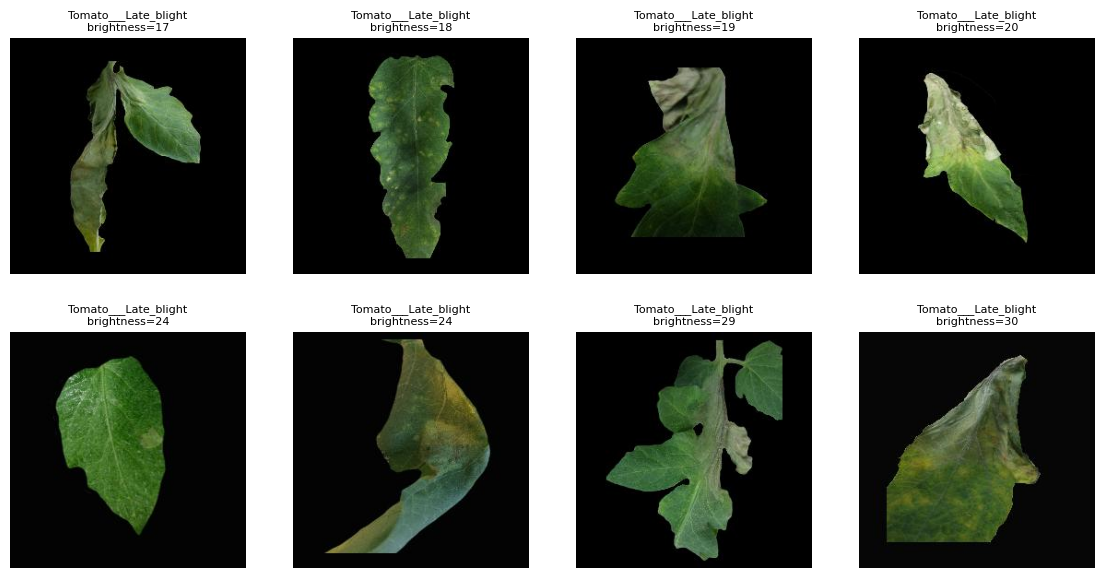

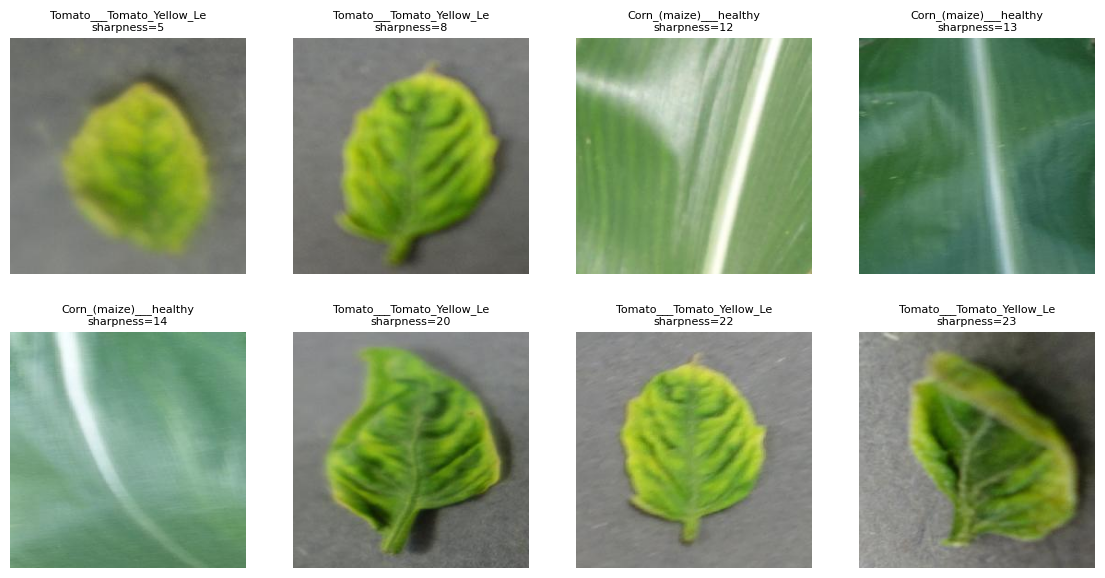

In [45]:
def show(rows, col):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        ax.imshow(cv2.cvtColor(cv2.imread(str(r["path"])), cv2.COLOR_BGR2RGB))
        ax.set_title(f'{r["label"][:25]}\n{col}={r[col]:.0f}', fontsize=8)
        ax.axis("off")
    plt.show()

show(sample.nsmallest(8, "brightness"), "brightness")
show(sample.nsmallest(8, "sharpness"), "sharpness")

In [46]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data_df, test_size=0.30, stratify=data_df["label"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42
)

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

Train: 37998 | Val: 8143 | Test: 8143


In [47]:
check = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "val":   val_df["label"].value_counts(normalize=True),
    "test":  test_df["label"].value_counts(normalize=True),
})
check.head(10)

,train,val,test
label,,,
Apple___Apple_scab,0.011606,0.011666,0.011544
Apple___Black_rot,0.011448,0.011421,0.011421
Apple___Cedar_apple_rust,0.005079,0.005035,0.005035
Apple___healthy,0.030186,0.030210,0.030087
Blueberry___healthy,0.027659,0.027631,0.027754
Cherry_(including_sour)___Powdery_mildew,0.019369,0.019403,0.019403
Cherry_(including_sour)___healthy,0.015738,0.015719,0.015719
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.009448,0.009456,0.009456
Corn_(maize)___Common_rust_,0.021949,0.021982,0.021982


In [48]:
classes = sorted(data_df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
print(len(classes), "classes")

38 classes


In [49]:
!pip install -q albumentations

In [50]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [51]:
IMG_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

training transforms

In [52]:
train_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=0.05, rotate=(-20, 20), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=20, val_shift_limit=10, p=0.3),
    A.OneOf([A.GaussianBlur(p=1.0), A.MotionBlur(p=1.0)], p=0.2),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

In [53]:
eval_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

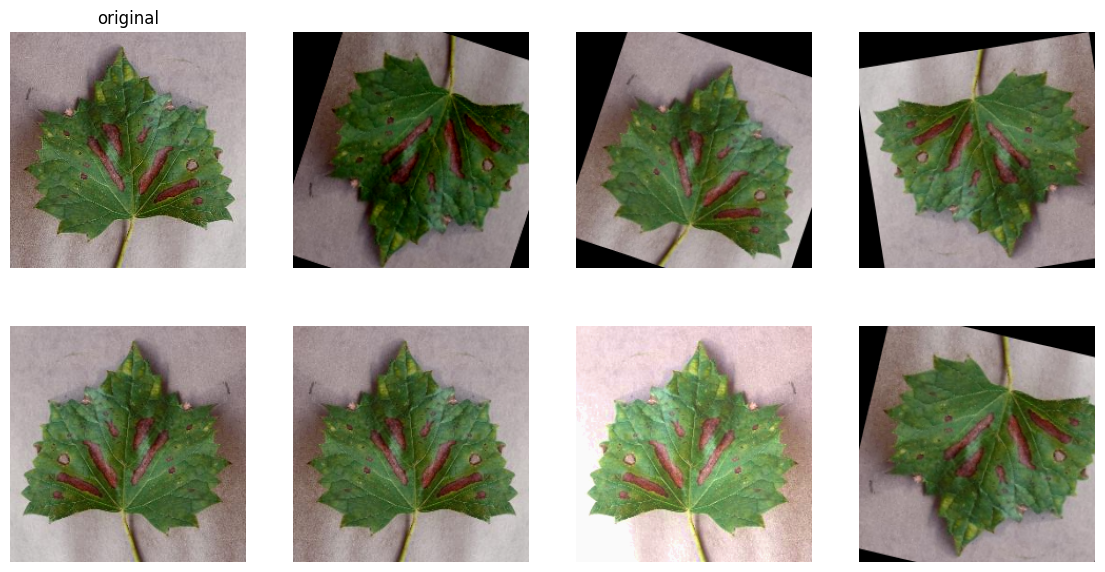

In [54]:
img = cv2.cvtColor(cv2.imread(str(train_df.iloc[0]["path"])), cv2.COLOR_BGR2RGB)

viz_tfms = A.Compose([t for t in train_tfms.transforms
                      if not isinstance(t, (A.Normalize, ToTensorV2))])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(img); axes[0, 0].set_title("original")
for ax in axes.flat[1:]:
    ax.imshow(viz_tfms(image=img)["image"])
for ax in axes.flat:
    ax.axis("off")
plt.show()

In [55]:
import torch
from torch.utils.data import Dataset, DataLoader

class LeafDataset(Dataset):
    def __init__(self, df, tfms):
        self.paths = df["path"].tolist()
        self.labels = df["label"].map(class_to_idx).tolist()
        self.tfms = tfms

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(str(self.paths[i])), cv2.COLOR_BGR2RGB)
        img = self.tfms(image=img)["image"]
        return img, self.labels[i]

In [56]:
train_ds = LeafDataset(train_df, train_tfms)
val_ds   = LeafDataset(val_df,   eval_tfms)
test_ds  = LeafDataset(test_df,  eval_tfms)

BATCH = 32
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

In [57]:
images, labels = next(iter(train_loader))
print(images.shape)
print(labels[:10])
print(images.min().item(), images.max().item())

torch.Size([32, 3, 224, 224])
tensor([30, 28, 10, 24, 28, 15, 35, 22, 34, 15])
-2.1179039478302 2.6399998664855957


In [58]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))


Using: cuda
Tesla T4


In [59]:
import torch.nn as nn
from torchvision import models

In [60]:
def build_model(name, num_classes=38, dropout=0.3):
    if name == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    else:
        raise ValueError("unknown model name")

    in_feats = m.classifier[1].in_features

    m.classifier = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(in_feats, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(512, num_classes),
    )
    return m

In [61]:
for name in ["mobilenet_v2", "efficientnet_b0"]:
    m = build_model(name)
    total = sum(p.numel() for p in m.parameters())
    print(f"{name}: {total/1e6:.2f}M parameters, about {total*4/1e6:.1f} MB")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 124MB/s]


mobilenet_v2: 2.90M parameters, about 11.6 MB
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 134MB/s]


efficientnet_b0: 4.68M parameters, about 18.7 MB


In [62]:
model = build_model("mobilenet_v2").to(device)
model.eval()

with torch.no_grad():
    out = model(images.to(device))

print(out.shape)

torch.Size([32, 38])


In [63]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

In [64]:
import time
import copy
import numpy as np
import torch

scaler = torch.amp.GradScaler("cuda")

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()

    total_loss, correct, n = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)

        with torch.set_grad_enabled(train):
            with torch.autocast("cuda"):
                out = model(imgs)
                loss = criterion(out, labels)

        if train:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        n += imgs.size(0)

    return total_loss / n, correct / n

In [65]:
def fit(model, optimizer, scheduler, epochs, patience=3, tag=""):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state, bad = 0.0, None, 0

    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)

        print(f"{tag} ep {ep+1}/{epochs} | train {tr_loss:.3f}/{tr_acc:.3f} | "
              f"val {va_loss:.3f}/{va_acc:.3f} | {time.time()-t0:.0f}s")

        if va_acc > best_acc:
            best_acc, best_state, bad = va_acc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping: no improvement.")
                break

    model.load_state_dict(best_state)
    return history, best_acc

In [66]:
model = build_model("mobilenet_v2").to(device)

for p in model.features.parameters():
    p.requires_grad = False

In [67]:
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)

hist1, acc1 = fit(model, optimizer, scheduler, epochs=5, patience=3, tag="Stage1")
print("Best val acc:", acc1)

Stage1 ep 1/5 | train 1.314/0.810 | val 0.946/0.945 | 142s
Stage1 ep 2/5 | train 1.166/0.860 | val 0.918/0.953 | 149s
Stage1 ep 3/5 | train 1.118/0.878 | val 0.892/0.961 | 147s
Stage1 ep 4/5 | train 1.091/0.889 | val 0.873/0.968 | 146s
Stage1 ep 5/5 | train 1.067/0.897 | val 0.872/0.965 | 146s
Best val acc: 0.9675795161488395


In [68]:
for p in model.features[-4:].parameters():
    p.requires_grad = True

In [69]:
optimizer = torch.optim.AdamW([
    {"params": model.features[-4:].parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(),    "lr": 1e-3},
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=8)

hist2, acc2 = fit(model, optimizer, scheduler, epochs=8, patience=3, tag="Stage2")
print("Best val acc:", acc2)

Stage2 ep 1/8 | train 0.996/0.921 | val 0.817/0.981 | 151s
Stage2 ep 2/8 | train 0.902/0.952 | val 0.785/0.989 | 154s
Stage2 ep 3/8 | train 0.867/0.963 | val 0.768/0.990 | 154s
Stage2 ep 4/8 | train 0.837/0.970 | val 0.753/0.992 | 152s
Stage2 ep 5/8 | train 0.822/0.974 | val 0.744/0.993 | 152s
Stage2 ep 6/8 | train 0.806/0.980 | val 0.739/0.993 | 150s
Stage2 ep 7/8 | train 0.797/0.981 | val 0.733/0.994 | 154s
Stage2 ep 8/8 | train 0.795/0.981 | val 0.733/0.994 | 151s
Best val acc: 0.9942281714355888


In [71]:
torch.save(model.state_dict(), "mobilenet_v2_best.pth")

In [72]:
model = build_model("efficientnet_b0").to(device)

In [73]:
src = lambda d: set(d["path"].map(lambda p: Path(p).stem.split("___")[-1]))
print("test sources also in train:", len(src(train_df) & src(test_df)), "/", len(src(test_df)))

test sources also in train: 435 / 8103


In [70]:
def train_backbone(name, unfreeze_last, ckpt):
    model = build_model(name).to(device)
    for p in model.features.parameters(): p.requires_grad = False
    opt = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=5)
    h1, _ = fit(model, opt, sch, 5, tag=f"{name}-S1")

    tail = model.features[-unfreeze_last:]
    for p in tail.parameters(): p.requires_grad = True
    opt = torch.optim.AdamW([{"params": tail.parameters(), "lr": 1e-4},
                             {"params": model.classifier.parameters(), "lr": 1e-3}],
                            weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=8)
    h2, best = fit(model, opt, sch, 8, tag=f"{name}-S2")
    torch.save(model.state_dict(), ckpt)
    return model, h1, h2, best

eff_model, eff_h1, eff_h2, eff_best = train_backbone("efficientnet_b0", 3, "effnet_b0_best.pth")

efficientnet_b0-S1 ep 1/5 | train 1.323/0.807 | val 0.964/0.943 | 150s
efficientnet_b0-S1 ep 2/5 | train 1.169/0.860 | val 0.930/0.953 | 152s
efficientnet_b0-S1 ep 3/5 | train 1.123/0.876 | val 0.904/0.959 | 155s
efficientnet_b0-S1 ep 4/5 | train 1.095/0.888 | val 0.889/0.964 | 155s
efficientnet_b0-S1 ep 5/5 | train 1.079/0.893 | val 0.881/0.964 | 155s
efficientnet_b0-S2 ep 1/8 | train 0.969/0.930 | val 0.794/0.986 | 164s
efficientnet_b0-S2 ep 2/8 | train 0.866/0.961 | val 0.766/0.990 | 160s
efficientnet_b0-S2 ep 3/8 | train 0.826/0.974 | val 0.743/0.994 | 169s
efficientnet_b0-S2 ep 4/8 | train 0.802/0.978 | val 0.725/0.995 | 161s
efficientnet_b0-S2 ep 5/8 | train 0.784/0.982 | val 0.720/0.996 | 159s
efficientnet_b0-S2 ep 6/8 | train 0.772/0.985 | val 0.714/0.996 | 159s
efficientnet_b0-S2 ep 7/8 | train 0.764/0.988 | val 0.709/0.997 | 161s
efficientnet_b0-S2 ep 8/8 | train 0.760/0.988 | val 0.709/0.997 | 160s


In [74]:
print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nClasses:")
print("Train:", train_df["label"].nunique())
print("Validation:", val_df["label"].nunique())
print("Test:", test_df["label"].nunique())

print("\nMissing classes in train:")
print(set(classes) - set(train_df["label"]))

print("\nMissing classes in validation:")
print(set(classes) - set(val_df["label"]))

print("\nMissing classes in test:")
print(set(classes) - set(test_df["label"]))

Train images: 37998
Validation images: 8143
Test images: 8143

Classes:
Train: 38
Validation: 38
Test: 38

Missing classes in train:
set()

Missing classes in validation:
set()

Missing classes in test:
set()


In [75]:
split_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).fillna(0)

split_counts["Train %"] = (
    split_counts["Train"] / len(train_df) * 100
)

split_counts["Validation %"] = (
    split_counts["Validation"] / len(val_df) * 100
)

split_counts["Test %"] = (
    split_counts["Test"] / len(test_df) * 100
)

display(split_counts)

,Train,Validation,Test,Train %,Validation %,Test %
label,,,,,,
Apple___Apple_scab,441,95,94,1.160587,1.166646,1.154366
Apple___Black_rot,435,93,93,1.144797,1.142085,1.142085
Apple___Cedar_apple_rust,193,41,41,0.507921,0.503500,0.503500
Apple___healthy,1147,246,245,3.018580,3.021000,3.008719
Blueberry___healthy,1051,225,226,2.765935,2.763109,2.775390
Cherry_(including_sour)___Powdery_mildew,736,158,158,1.936944,1.940317,1.940317
Cherry_(including_sour)___healthy,598,128,128,1.573767,1.571902,1.571902
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,359,77,77,0.944787,0.945597,0.945597
Corn_(maize)___Common_rust_,834,179,179,2.194852,2.198207,2.198207


Complete model development and training

In [76]:
for p in model.features.parameters():
    p.requires_grad = False

Fine-tune the backbone

In [77]:
for p in model.features[-4:].parameters():
    p.requires_grad = True

In [78]:
optimizer = torch.optim.AdamW([
    {
        "params": model.features[-4:].parameters(),
        "lr": 1e-4
    },
    {
        "params": model.classifier.parameters(),
        "lr": 1e-3
    }
], weight_decay=1e-4)

model performance

In [82]:
import torch
from torchvision import models

In [83]:

# Evaluate the fine-tuned EfficientNetB0 model

test_loss, test_accuracy = run_epoch(
    eff_model,
    test_loader,
    criterion
)

print("========== EFFICIENTNETB0 TEST RESULTS ==========")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


========== EFFICIENTNETB0 TEST RESULTS ==========
Test Loss: 0.7118
Test Accuracy: 99.55 %


classification report

In [84]:

from sklearn.metrics import classification_report
import torch

eff_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        with torch.autocast("cuda"):
            outputs = eff_model(images)

        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))


                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        94
                                 Apple___Black_rot       1.00      1.00      1.00        93
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        41
                                   Apple___healthy       1.00      1.00      1.00       245
                               Blueberry___healthy       1.00      1.00      1.00       226
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       158
                 Cherry_(including_sour)___healthy       1.00      0.99      1.00       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.97      0.83      0.90        77
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       179
               Corn_(maize)___Northern_Leaf_Blight       0.92      0.98      0.

Generating  the confusion matrix

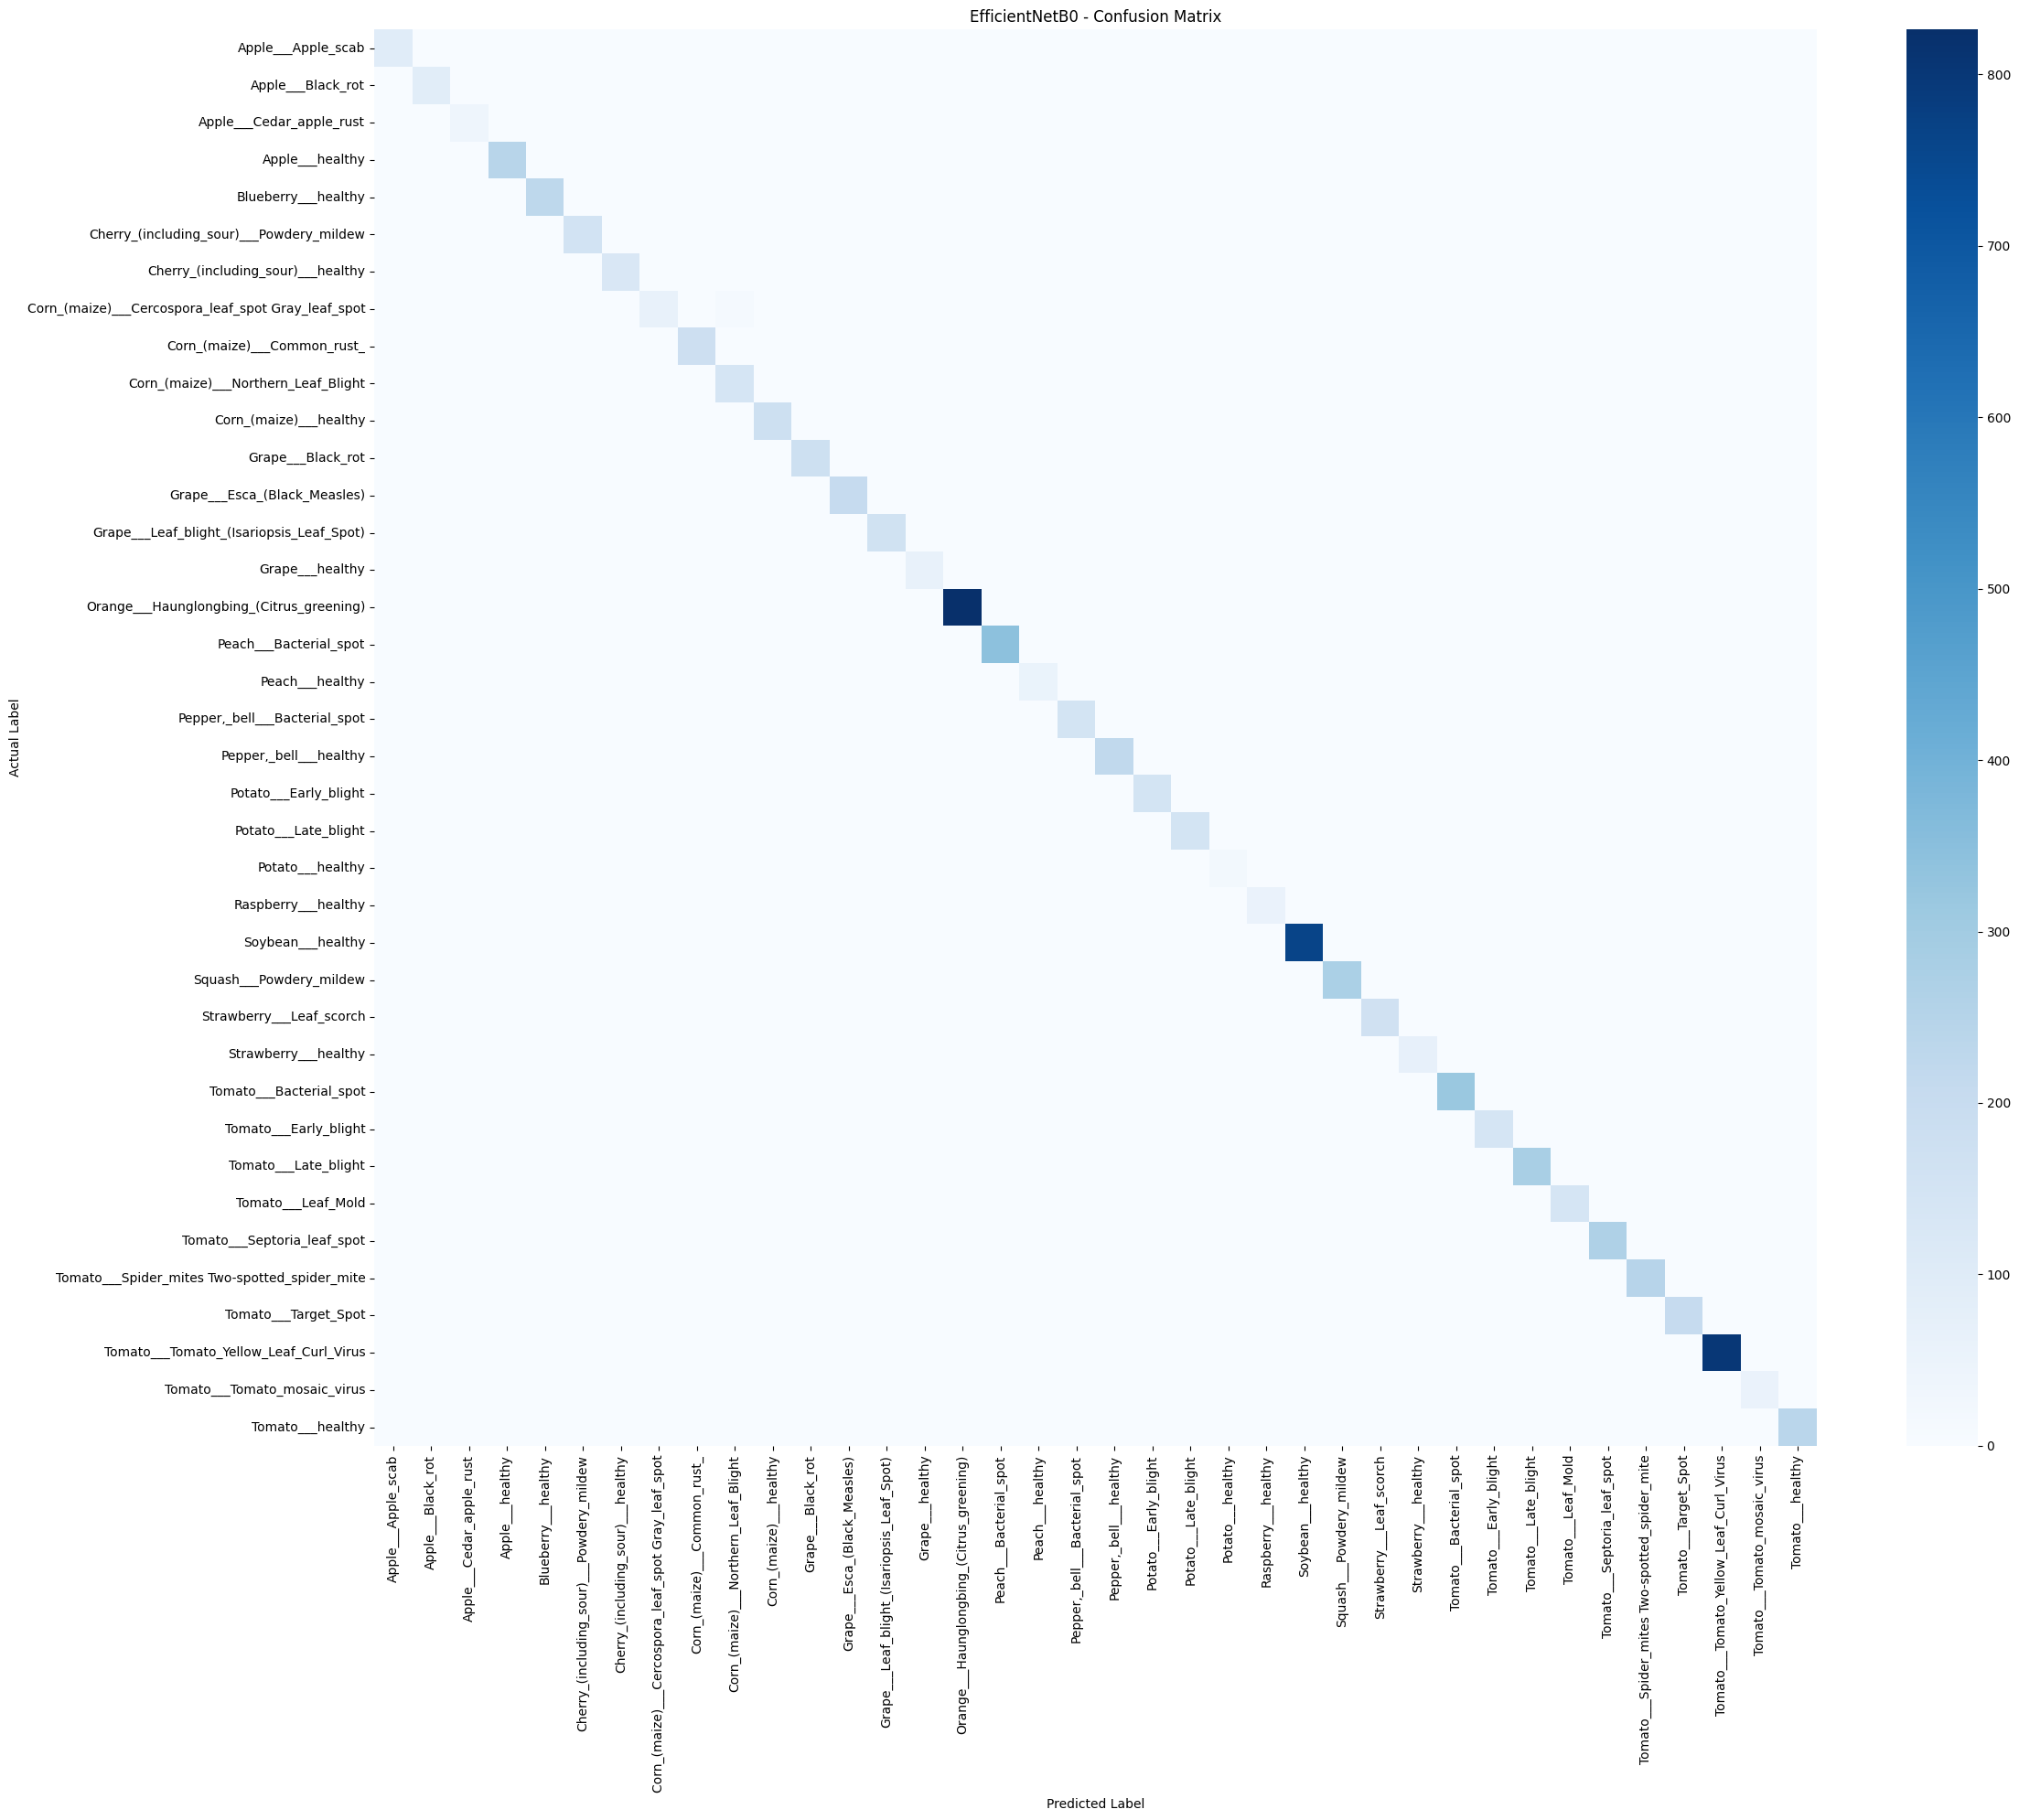

In [85]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
)

# Plot confusion matrix
plt.figure(figsize=(24, 20))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    annot=False,
    fmt="d"
)

plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


Finding misclassified images

In [86]:

import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
)

# Remove correct predictions from the diagonal
np.fill_diagonal(cm, 0)

# Find class pairs with the most errors
error_pairs = []

for actual_idx in range(len(classes)):
    for predicted_idx in range(len(classes)):

        count = cm[actual_idx, predicted_idx]

        if count > 0:
            error_pairs.append((
                classes[actual_idx],
                classes[predicted_idx],
                count
            ))

error_pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 10 misclassification pairs:")

for actual, predicted, count in error_pairs[:10]:
    print(f"Actual: {actual}")
    print(f"Predicted: {predicted}")
    print(f"Incorrect predictions: {count}")
    print("-" * 50)


Top 10 misclassification pairs:
Actual: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Predicted: Corn_(maize)___Northern_Leaf_Blight
Incorrect predictions: 13
--------------------------------------------------
Actual: Tomato___Spider_mites Two-spotted_spider_mite
Predicted: Tomato___Target_Spot
Incorrect predictions: 3
--------------------------------------------------
Actual: Corn_(maize)___Northern_Leaf_Blight
Predicted: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Incorrect predictions: 2
--------------------------------------------------
Actual: Tomato___Early_blight
Predicted: Tomato___Spider_mites Two-spotted_spider_mite
Incorrect predictions: 2
--------------------------------------------------
Actual: Tomato___Early_blight
Predicted: Tomato___Target_Spot
Incorrect predictions: 2
--------------------------------------------------
Actual: Tomato___Late_blight
Predicted: Tomato___healthy
Incorrect predictions: 2
--------------------------------------------------
Actual:

Calculating the  exact test accuracy

In [87]:

from sklearn.metrics import accuracy_score

exact_accuracy = accuracy_score(
    all_labels,
    all_preds
)

print("Exact Test Accuracy:", exact_accuracy)
print("Test Accuracy (%):", exact_accuracy * 100)


Exact Test Accuracy: 0.9954562200663146
Test Accuracy (%): 99.54562200663146


Confusion Matrix

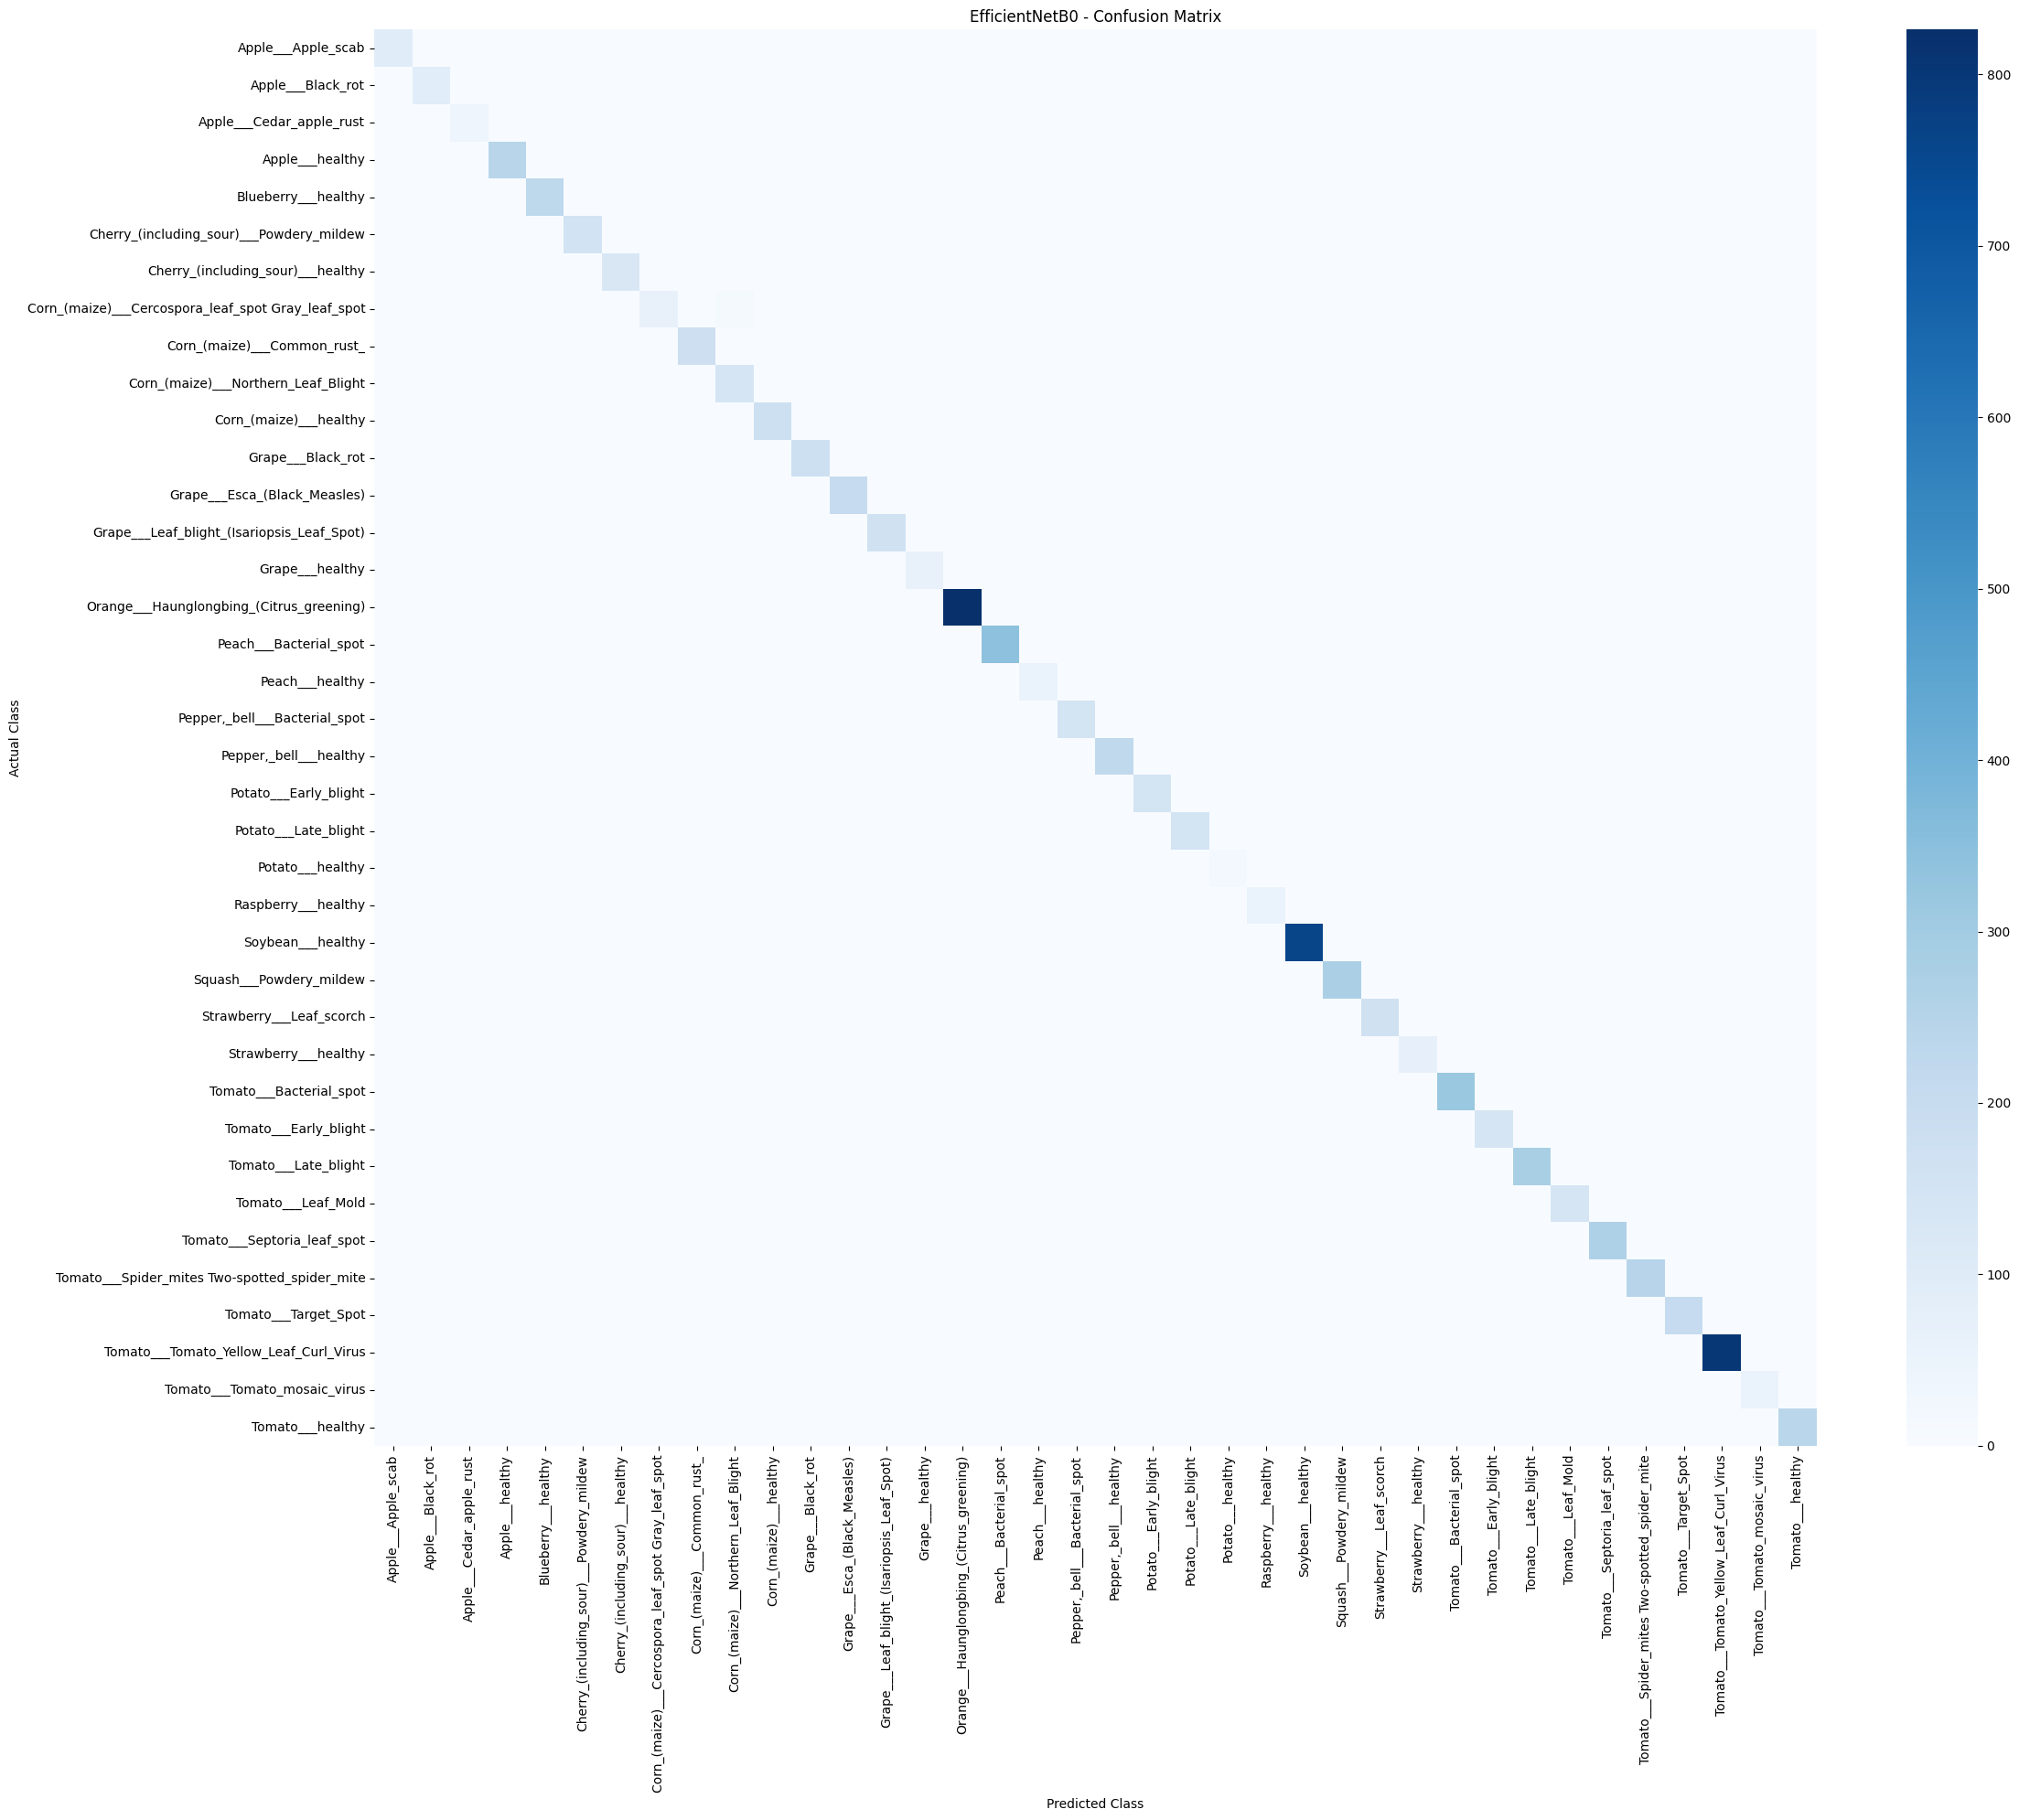

In [88]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
)

# Plot
plt.figure(figsize=(24, 20))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    annot=False,
    fmt="d"
)

plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


Misclassification analysis

In [89]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
)

# Remove correct predictions
error_matrix = cm.copy()
np.fill_diagonal(error_matrix, 0)

# Find misclassification pairs
errors = []

for actual_idx in range(len(classes)):
    for predicted_idx in range(len(classes)):

        count = error_matrix[actual_idx, predicted_idx]

        if count > 0:
            errors.append({
                "Actual Disease": classes[actual_idx],
                "Predicted Disease": classes[predicted_idx],
                "Incorrect Predictions": int(count)
            })

# Sort by number of errors
error_df = pd.DataFrame(errors)

if len(error_df) > 0:
    error_df = error_df.sort_values(
        by="Incorrect Predictions",
        ascending=False
    )

    print("Top 10 Misclassification Errors")
    display(error_df.head(10))
else:
    print("No misclassified images found.")


Top 10 Misclassification Errors


,Actual Disease,Predicted Disease,Incorrect Predictions
1,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,13
14,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,3
13,Tomato___Late_blight,Tomato___healthy,2
2,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,2
10,Tomato___Early_blight,Tomato___Target_Spot,2
9,Tomato___Early_blight,Tomato___Spider_mites Two-spotted_spider_mite,2
17,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite,2
0,Cherry_(including_sour)___healthy,Soybean___healthy,1
4,Grape___Black_rot,Grape___Esca_(Black_Measles),1
3,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___healthy,1


In [91]:

# Rebuild MobileNetV2 architecture
mobile_model = build_model("mobilenet_v2").to(device)

# Load the saved fine-tuned weights
mobile_model.load_state_dict(
    torch.load(
        "mobilenet_v2_best.pth",
        map_location=device
    )
)

# Set model to evaluation mode
mobile_model.eval()

print("MobileNetV2 model loaded successfully")


MobileNetV2 model loaded successfully


In [92]:

# Evaluate MobileNetV2 on the test dataset

mobile_test_loss, mobile_test_acc = run_epoch(
    mobile_model,
    test_loader,
    criterion
)

print("========== MOBILENETV2 TEST RESULTS ==========")
print("Test Loss:", round(mobile_test_loss, 4))
print("Test Accuracy:", round(mobile_test_acc * 100, 2), "%")


========== MOBILENETV2 TEST RESULTS ==========
Test Loss: 0.7358
Test Accuracy: 99.23 %


In [93]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["MobileNetV2", "EfficientNetB0"],
    "Test Accuracy (%)": [
        mobile_test_acc * 100,
        test_accuracy * 100
    ],
    "Test Loss": [
        mobile_test_loss,
        test_loss
    ]
})

display(comparison)


,Model,Test Accuracy (%),Test Loss
0,MobileNetV2,99.226329,0.735849
1,EfficientNetB0,99.545622,0.711793


Visualize actual plant disease predictions

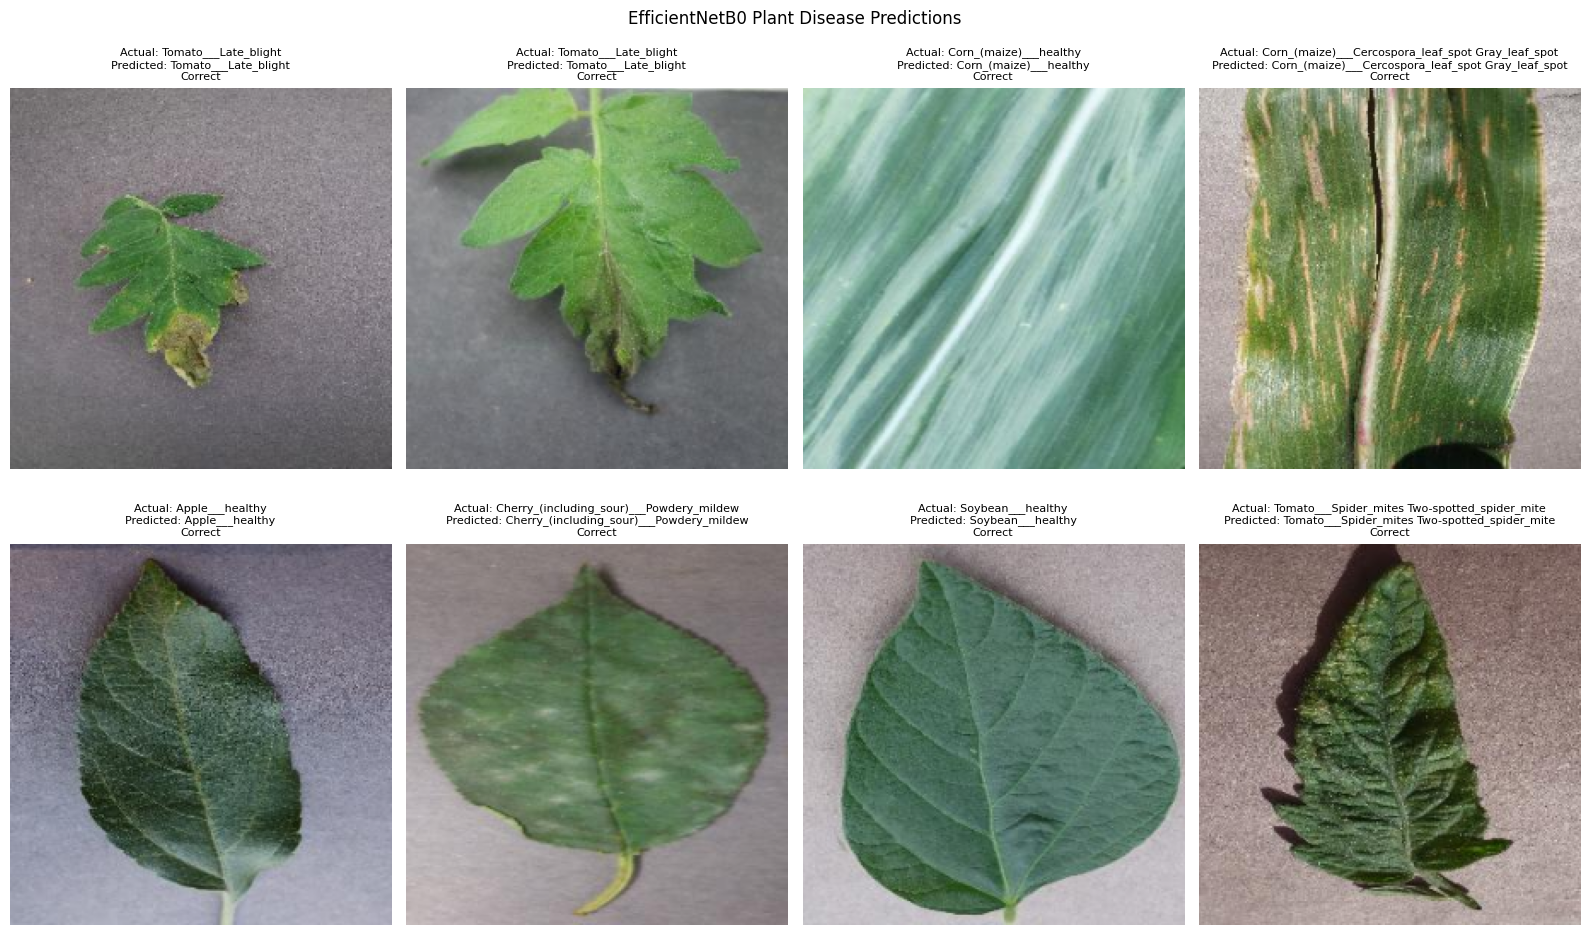

In [94]:

import matplotlib.pyplot as plt
import torch
import numpy as np

# Use the best model
eff_model.eval()

# ImageNet normalization values used in your notebook
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

# Get a batch of test images
images, labels = next(iter(test_loader))

images_device = images.to(device)

# Predict
with torch.no_grad():
    with torch.autocast("cuda"):
        outputs = eff_model(images_device)

    predictions = outputs.argmax(dim=1)

# Display predictions
plt.figure(figsize=(16, 10))

for i in range(min(8, len(images))):

    # Convert image back to normal RGB
    img = images[i].cpu() * std + mean
    img = img.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    actual = classes[labels[i].item()]
    predicted = classes[predictions[i].item()]

    correct = actual == predicted

    plt.subplot(2, 4, i + 1)

    plt.imshow(img)

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\n"
        f"{'Correct' if correct else 'Incorrect'}",
        fontsize=8
    )

    plt.axis("off")

plt.suptitle("EfficientNetB0 Plant Disease Predictions")
plt.tight_layout()
plt.show()


In [95]:

import torch

# Save the best EfficientNetB0 model
torch.save(
    eff_model.state_dict(),
    "final_plant_disease_model.pth"
)

print("Final model saved successfully!")


Final model saved successfully!


Model Optimization

Measuring the original model

In [96]:

import torch
import os
import time

# Use the saved EfficientNetB0 model
eff_model.eval()
eff_model.to(device)

# 1. Model size
model_path = "final_plant_disease_model.pth"

model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

# 2. Number of parameters
total_params = sum(
    p.numel() for p in eff_model.parameters()
)

trainable_params = sum(
    p.numel() for p in eff_model.parameters()
    if p.requires_grad
)

# 3. Prepare test batch
images, labels = next(iter(test_loader))
images = images.to(device)

# 4. Warm-up
with torch.no_grad():
    for _ in range(10):
        outputs = eff_model(images)

if device.type == "cuda":
    torch.cuda.synchronize()

# 5. Measure inference time
iterations = 50

start_time = time.perf_counter()

with torch.no_grad():
    for _ in range(iterations):
        outputs = eff_model(images)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_time = end_time - start_time

batch_size = images.shape[0]

avg_batch_time_ms = (
    total_time / iterations
) * 1000

avg_image_time_ms = (
    total_time / (iterations * batch_size)
) * 1000

throughput = (
    iterations * batch_size
) / total_time

# 6. Display results
print("========== ORIGINAL MODEL BASELINE ==========")

print("Model: EfficientNetB0")
print("Test Accuracy: 99.5456%")

print("Model Size:", round(model_size_mb, 2), "MB")

print("Total Parameters:", f"{total_params:,}")

print("Trainable Parameters:", f"{trainable_params:,}")

print("Average Batch Inference Time:",
      round(avg_batch_time_ms, 2), "ms")

print("Average Inference Time Per Image:",
      round(avg_image_time_ms, 2), "ms")

print("Inference Throughput:",
      round(throughput, 2), "images/second")


========== ORIGINAL MODEL BASELINE ==========
Model: EfficientNetB0
Test Accuracy: 99.5456%
Model Size: 18.17 MB
Total Parameters: 4,683,938
Trainable Parameters: 3,832,130
Average Batch Inference Time: 41.57 ms
Average Inference Time Per Image: 1.3 ms
Inference Throughput: 769.74 images/second


dynamic quantization

In [97]:

import torch
import torch.nn as nn
import copy
import os
import time

# Create a CPU copy of EfficientNetB0
cpu_model = copy.deepcopy(eff_model).cpu().eval()

# Apply dynamic quantization to Linear layers
quantized_model = torch.ao.quantization.quantize_dynamic(
    cpu_model,
    {nn.Linear},
    dtype=torch.qint8
)

# Save quantized model
quantized_path = "efficientnetb0_dynamic_quantized.pth"

torch.save(
    quantized_model.state_dict(),
    quantized_path
)

# Measure quantized model size
quantized_size_mb = (
    os.path.getsize(quantized_path) / (1024 * 1024)
)

print("========== QUANTIZED MODEL ==========")
print("Quantized Model Size:",
      round(quantized_size_mb, 2), "MB")

# Evaluate quantized model on CPU
quantized_model.eval()

correct = 0
total = 0

start_time = time.perf_counter()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.cpu()
        labels = labels.cpu()

        outputs = quantized_model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

end_time = time.perf_counter()

quantized_accuracy = correct / total

quantized_time = end_time - start_time

quantized_throughput = total / quantized_time

print("Quantized Test Accuracy:",
      round(quantized_accuracy * 100, 4), "%")

print("CPU Evaluation Time:",
      round(quantized_time, 2), "seconds")

print("CPU Throughput:",
      round(quantized_throughput, 2), "images/second")


/tmp/ipykernel_3174/3492680112.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.ao.quantization.quantize_dynamic(


========== QUANTIZED MODEL ==========
Quantized Model Size: 16.23 MB
Quantized Test Accuracy: 99.5456 %
CPU Evaluation Time: 562.59 seconds
CPU Throughput: 14.47 images/second


Checking quantized accuracy and inference speed

In [98]:

print("========== QUANTIZATION RESULTS ==========")

print("Original Model Size: 18.17 MB")
print("Quantized Model Size:", round(quantized_size_mb, 2), "MB")

print("Original Test Accuracy: 99.5456%")

print("Quantized Test Accuracy:",
      round(quantized_accuracy * 100, 4), "%")

print("Quantized CPU Throughput:",
      round(quantized_throughput, 2), "images/second")

print("Model Size Reduction:",
      round(18.17 - quantized_size_mb, 2), "MB")

print("Size Reduction Percentage:",
      round((18.17 - quantized_size_mb) / 18.17 * 100, 2), "%")


========== QUANTIZATION RESULTS ==========
Original Model Size: 18.17 MB
Quantized Model Size: 16.23 MB
Original Test Accuracy: 99.5456%
Quantized Test Accuracy: 99.5456 %
Quantized CPU Throughput: 14.47 images/second
Model Size Reduction: 1.94 MB
Size Reduction Percentage: 10.66 %


Model Pruning

Import pruning tools

In [99]:
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune
import copy
import os

copy of EfficientNetB0

In [100]:
pruned_model = copy.deepcopy(eff_model)
pruned_model.eval()

print("Original model copied successfully")

Original model copied successfully


Apply pruning

In [101]:
parameters_to_prune = []

for name, module in pruned_model.named_modules():

    if isinstance(module, (nn.Conv2d, nn.Linear)):

        parameters_to_prune.append((module, "weight"))

prune.global_unstructured(
    parameters_to_prune,
    pruning_method=prune.L1Unstructured,
    amount=0.20
)

print("20% pruning applied successfully")

20% pruning applied successfully


Make pruning permanent

In [102]:
for module, parameter_name in parameters_to_prune:

    prune.remove(module, parameter_name)

print("Pruning made permanent")

Pruning made permanent


Save the pruned model

In [105]:
import torch.nn.utils.prune as prune

removed_count = 0
skipped_count = 0

for module, parameter_name in parameters_to_prune:

    if hasattr(module, parameter_name + "_orig") and \
       hasattr(module, parameter_name + "_mask"):

        prune.remove(module, parameter_name)
        removed_count += 1

    else:
        skipped_count += 1

print("Pruning made permanent")
print("Layers processed:", removed_count)
print("Layers skipped:", skipped_count)

Pruning made permanent
Layers processed: 0
Layers skipped: 83


In [106]:
total_params = 0
zero_params = 0

for module in pruned_model.modules():

    if isinstance(module, (nn.Conv2d, nn.Linear)):

        weights = module.weight.detach()

        total_params += weights.numel()
        zero_params += (weights == 0).sum().item()

actual_sparsity = 100 * zero_params / total_params

print("Total weights:", total_params)
print("Zero weights:", zero_params)
print("Actual sparsity:", round(actual_sparsity, 2), "%")

Total weights: 4631008
Zero weights: 926202
Actual sparsity: 20.0 %


In [107]:
torch.save(
    pruned_model.state_dict(),
    "efficientnetb0_pruned.pth"
)

print("Pruned model saved successfully")

Pruned model saved successfully


Measure model size

In [108]:
original_size = os.path.getsize(
    "final_plant_disease_model.pth"
) / (1024 * 1024)

pruned_size = os.path.getsize(
    "efficientnetb0_pruned.pth"
) / (1024 * 1024)

print("Original Model Size:", round(original_size, 2), "MB")
print("Pruned Model Size:", round(pruned_size, 2), "MB")

print(
    "Size Reduction:",
    round(original_size - pruned_size, 2),
    "MB"
)

Original Model Size: 18.17 MB
Pruned Model Size: 18.16 MB
Size Reduction: 0.0 MB


Evaluate pruned model accuracy

In [109]:
pruned_model = pruned_model.to(device)
pruned_model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = pruned_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

pruned_accuracy = 100 * correct / total

print("Pruned Test Accuracy:", round(pruned_accuracy, 4), "%")

Pruned Test Accuracy: 99.5088 %


In [110]:
!pip install gradio

Load your trained model

In [111]:
import torch
import gradio as gr
from PIL import Image
import torchvision.transforms as transforms

eff_model.eval()

print("EfficientNetB0 loaded")
print("Number of classes:", len(classes))

EfficientNetB0 loaded
Number of classes: 38


Create the image preprocessing function

In [112]:
# Use the same MEAN and STD from your project

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=MEAN,
        std=STD
    )
])

Create the prediction function

In [113]:
def predict_image(image):

    if image is None:
        return {}

    image = image.convert("RGB")

    image_tensor = transform(image).unsqueeze(0)
    image_tensor = image_tensor.to(device)

    eff_model.eval()

    with torch.no_grad():

        outputs = eff_model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

        top_probabilities, top_indices = torch.topk(
            probabilities,
            k=3,
            dim=1
        )

    results = {}

    for probability, index in zip(
        top_probabilities[0],
        top_indices[0]
    ):

        class_name = classes[index.item()]

        confidence = probability.item()

        results[class_name] = confidence

    return results

Build the Gradio interface

In [114]:
demo = gr.Interface(
    fn=predict_image,

    inputs=gr.Image(
        type="pil",
        label="Upload a Plant Leaf Image"
    ),

    outputs=gr.Label(
        num_top_classes=3,
        label="Predicted Plant Disease"
    ),

    title="Plant Disease Classification",

    description=(
        "Upload a plant leaf image. "
        "The EfficientNetB0 model predicts "
        "the possible plant disease."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fc11b654a7eda5f33d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Calculate the accuracy difference

In [115]:
original_accuracy = 99.5456
quantized_accuracy = 99.5456
pruned_accuracy = 99.5088

print("Original Accuracy:", original_accuracy, "%")

print(
    "Quantized Accuracy:",
    quantized_accuracy,
    "%"
)

print(
    "Pruned Accuracy:",
    pruned_accuracy,
    "%"
)

print(
    "Quantized Accuracy Loss:",
    round(original_accuracy - quantized_accuracy, 4),
    "percentage points"
)

print(
    "Pruned Accuracy Loss:",
    round(original_accuracy - pruned_accuracy, 4),
    "percentage points"
)

Original Accuracy: 99.5456 %
Quantized Accuracy: 99.5456 %
Pruned Accuracy: 99.5088 %
Quantized Accuracy Loss: 0.0 percentage points
Pruned Accuracy Loss: 0.0368 percentage points


Final conclusion
Based on the results supplied:
- Original EfficientNetB0: Highest measured accuracy, 99.5456%.
- Quantized EfficientNetB0: Same measured accuracy, with 10.66% smaller model size.
- Pruned EfficientNetB0: Nearly the same accuracy, but negligible saved-file size reduction.
The quantized model is the strongest optimization result so far because it reduced model size without changing the reported test accuracy.

Deployment insights
project report, the important findings are:
1. EfficientNetB0 achieved high classification accuracy on the PlantVillage test set.
2. Quantization reduced the saved model size from 18.17 MB to 16.23 MB while retaining 99.5456% test accuracy.
3. Unstructured pruning produced almost no reduction in the saved checkpoint size.
4. The Gradio demo successfully accepted an uploaded image and returned the top three predicted disease classes.
5. The demo's internet-image example produced a top confidence of 27%, showing why confidence-based warnings can be useful.
6. The model should be tested on diverse real-world leaf images before claiming reliable field deployment.